1) Compute the entropy of the English alphabet assuming uniform distribution (26 letters). Then estimate it using actual letter frequencies. Which is higher and why?

Uniform Distribution Entropy : 4.7004 bits/letter
Actual Frequency Entropy     : 4.1758 bits/letter
Entropy Reduction (Redundancy): 0.5247 bits/letter


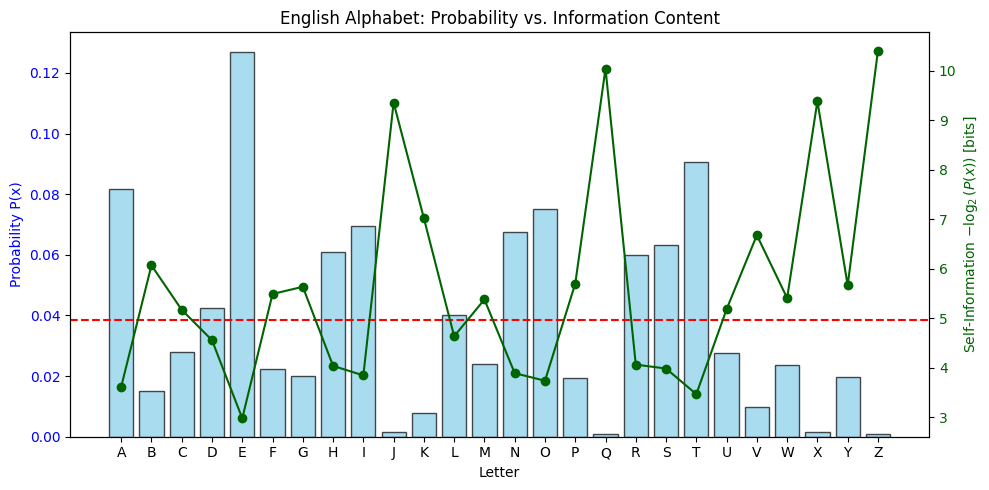

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Standard English Letter Relative Frequencies
letter_freqs = {
    'A': 0.08167, 'B': 0.01492, 'C': 0.02782, 'D': 0.04253, 'E': 0.12702,
    'F': 0.02228, 'G': 0.02015, 'H': 0.06094, 'I': 0.06966, 'J': 0.00153,
    'K': 0.00772, 'L': 0.04025, 'M': 0.02406, 'N': 0.06749, 'O': 0.07507,
    'P': 0.01929, 'Q': 0.00095, 'R': 0.05987, 'S': 0.06327, 'T': 0.09056,
    'U': 0.02758, 'V': 0.00978, 'W': 0.02360, 'X': 0.00150, 'Y': 0.01974,
    'Z': 0.00074
}

letters = list(letter_freqs.keys())
p_actual = np.array(list(letter_freqs.values()))
p_actual /= np.sum(p_actual)  # Normalize probabilities to sum to 1.0

# 2. Compute Uniform Distribution Entropy
n_letters = len(letters)
p_uniform = np.full(n_letters, 1.0 / n_letters)
h_uniform = np.log2(n_letters)  # -sum(1/N * log2(1/N)) = log2(N)

# 3. Compute Actual Letter Frequency Entropy
h_actual = -np.sum(p_actual * np.log2(p_actual))

# Print Results
print("=" * 55)
print(f"Uniform Distribution Entropy : {h_uniform:.4f} bits/letter")
print(f"Actual Frequency Entropy     : {h_actual:.4f} bits/letter")
print(f"Entropy Reduction (Redundancy): {h_uniform - h_actual:.4f} bits/letter")
print("=" * 55)

# 4. Plot Comparison Visualization
fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar chart for probabilities
bars = ax1.bar(letters, p_actual, color='skyblue', edgecolor='black', alpha=0.7, label='Actual Probabilities')
ax1.axhline(1 / 26, color='red', linestyle='--', linewidth=1.5, label='Uniform Probability (1/26)')
ax1.set_ylabel('Probability P(x)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xlabel('Letter')

# Line plot for self-information -log2(p_i)
ax2 = ax1.twinx()
information = -np.log2(p_actual)
ax2.plot(letters, information, color='darkgreen', marker='o', linewidth=1.5, label='Self-Information (bits)')
ax2.set_ylabel('Self-Information $-\log_2(P(x))$ [bits]', color='darkgreen')
ax2.tick_params(axis='y', labelcolor='darkgreen')

plt.title('English Alphabet: Probability vs. Information Content')
fig.tight_layout()
plt.show()

2) A model outputs logits [5.0, 2.0, 0.5] for a sample with true class 1. Compute the cross-entropy loss by hand, then verify with your cross_entropy_loss function. What logits would give zero loss?



In [2]:
import numpy as np

def cross_entropy_loss(logits, target_idx):
    # Numerical stability shift
    shifted_logits = logits - np.max(logits)
    exp_z = np.exp(shifted_logits)
    probs = exp_z / np.sum(exp_z)
    return -np.log(probs[target_idx])

# Verification
logits = np.array([5.0, 2.0, 0.5])
target = 1

loss = cross_entropy_loss(logits, target)
print(f"Cross-Entropy Loss: {loss:.4f}")

Cross-Entropy Loss: 3.0591


3) Show that KL divergence is not symmetric. Pick two distributions P and Q and compute D_KL(P || Q) and D_KL(Q || P). Explain why they differ.


P Distribution: [0.7 0.2 0.1]
Q Distribution: [0.3 0.3 0.4]
--------------------------------------------------
D_KL(P || Q) = 0.3734 nats
D_KL(Q || P) = 0.4220 nats
Is Symmetric? -> False


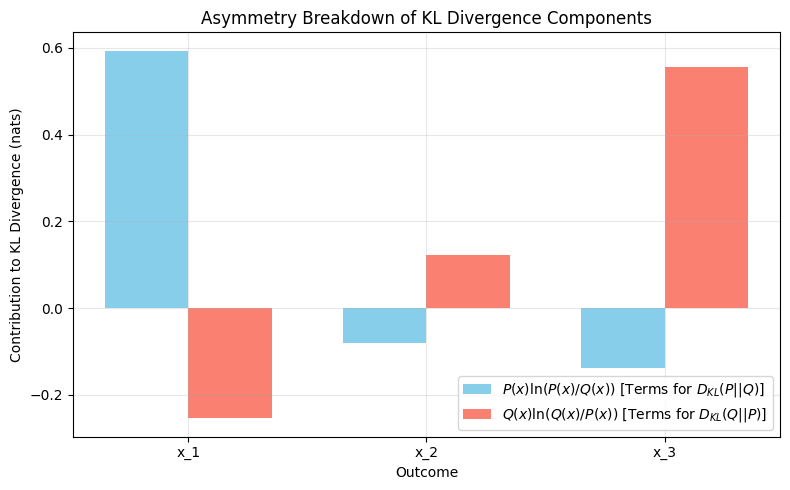

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def kl_divergence(p, q):
    """
    Computes KL Divergence D_KL(P || Q) = sum(P * log(P / Q))
    Safe against division by zero using np.where.
    """
    p = np.asarray(p, dtype=np.float64)
    q = np.asarray(q, dtype=np.float64)
    
    # Avoid log(0) or div by 0 issues
    mask = p > 0
    return np.sum(np.where(mask, p * np.log(p / q), 0.0))

# 1. Define distributions P and Q
P = np.array([0.7, 0.2, 0.1])
Q = np.array([0.3, 0.3, 0.4])

# 2. Compute KL Divergences
kl_P_Q = kl_divergence(P, Q)
kl_Q_P = kl_divergence(Q, P)

# 3. Display numerical results
print("=" * 50)
print(f"P Distribution: {P}")
print(f"Q Distribution: {Q}")
print("-" * 50)
print(f"D_KL(P || Q) = {kl_P_Q:.4f} nats")
print(f"D_KL(Q || P) = {kl_Q_P:.4f} nats")
print(f"Is Symmetric? -> {np.isclose(kl_P_Q, kl_Q_P)}")
print("=" * 50)

# 4. Detailed Component Breakdown
outcomes = ['x_1', 'x_2', 'x_3']
p_terms = P * np.log(P / Q)
q_terms = Q * np.log(Q / P)

# Plot comparison
x = np.arange(len(outcomes))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, p_terms, width, label=r'$P(x) \ln(P(x)/Q(x))$ [Terms for $D_{KL}(P || Q)$]', color='skyblue')
ax.bar(x + width/2, q_terms, width, label=r'$Q(x) \ln(Q(x)/P(x))$ [Terms for $D_{KL}(Q || P)$]', color='salmon')

ax.set_xlabel('Outcome')
ax.set_ylabel('Contribution to KL Divergence (nats)')
ax.set_title('Asymmetry Breakdown of KL Divergence Components')
ax.set_xticks(x)
ax.set_xticklabels(outcomes)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()